# 23｜先打好光：夜间补光和像素

目标是知道“画面更亮”为什么不一定“焊纹更清楚”。本课读取真实焊缝照片，再人为降低亮度、加噪声和模糊，做可重复的派生演示。这些图不是现场夜间实测，也不是不同灯具的实拍对比。

暗环境表示环境光不足；**光学暗场**是一种低角度照明布置，让平面直接反光偏离镜头、让纹理和边缘散射入镜。二者不能混用。对于反光金属，可先比较大面积漫射光和左右低角度条形光：漫射光用于定位，侧光用于看纹理。偏振对裸金属的改善可能有限，需实际比较。

参考：[Basler 照明基础](https://www.baslerweb.com/en/learning/illumination/)、[暗场照明](https://www.baslerweb.com/en/illumination/dark-field-light/)。以下只演示像素变化，不宣称复现这些光学布置。

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "course_utils.py").is_file())
INDUSTRIAL_ROOT = ROOT / "courses" / "industrial-vision-lab"
if str(INDUSTRIAL_ROOT) not in sys.path:
    sys.path.insert(0, str(INDUSTRIAL_ROOT))
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
import lab_utils as lab
print("OpenCV", cv2.__version__, "| NumPy", np.__version__)

OpenCV 4.12.0 | NumPy 2.2.6


/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 27966 (\N{CJK UNIFIED IDEOGRAPH-6D3E}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/

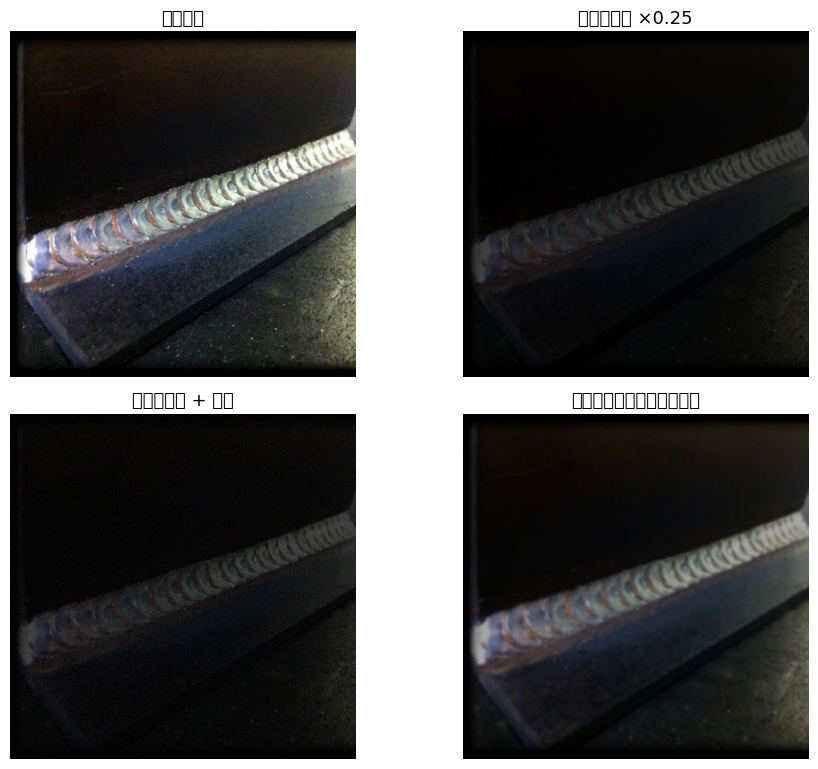

原图 {'brightness': 48.829, 'sharpness': 207.265, 'dark_ratio': 0.33159, 'overexposed_ratio': 0.00843, 'width': 640, 'height': 640}
低亮 {'brightness': 11.826, 'sharpness': 14.43, 'dark_ratio': 0.8064, 'overexposed_ratio': 0.0, 'width': 640, 'height': 640}
低亮噪声 {'brightness': 13.033, 'sharpness': 515.604, 'dark_ratio': 0.78935, 'overexposed_ratio': 0.0, 'width': 640, 'height': 640}
模糊 {'brightness': 31.249, 'sharpness': 2.309, 'dark_ratio': 0.49808, 'overexposed_ratio': 0.0, 'width': 640, 'height': 640}


In [2]:
image = lab.load_case("weld_good")
dark = lab.degrade(image, 0.25)
dark_noisy = lab.degrade(image, 0.25, noise=9)
blurred = lab.degrade(image, 0.65, blur=11)
lab.show_images([image, dark, dark_noisy, blurred],
                ["真实原图", "派生：亮度 ×0.25", "派生：低亮 + 噪声", "派生：模糊，模拟细节丢失"], cols=2)
for name, sample in [("原图", image), ("低亮", dark), ("低亮噪声", dark_noisy), ("模糊", blurred)]:
    print(name, lab.image_quality(sample))

## 1. 看四个指标，但不迷信它们

平均灰度描述整体明暗；过暗/过曝比例描述落在极端范围的像素；拉普拉斯方差可作为清晰度线索。噪声也会使方差变大，所以“分数高”不能独自证明对焦正确。整图指标还会被黑背景或亮金属误导，最终要在镍片焊纹 ROI 上测。

/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 28784 (\N{CJK UNIFIED IDEOGRAPH-7070}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 21442 (\N{CJK UNIFIED IDEOGRAPH-53C2}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 32771 (\N{CJK UNIFIED IDEOGRAPH-8003}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 20877 (\N{CJK UNIFIED IDEOGRAPH-518D}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 25918 (\N{CJK UNIFIED IDEOGRAPH-653E}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/

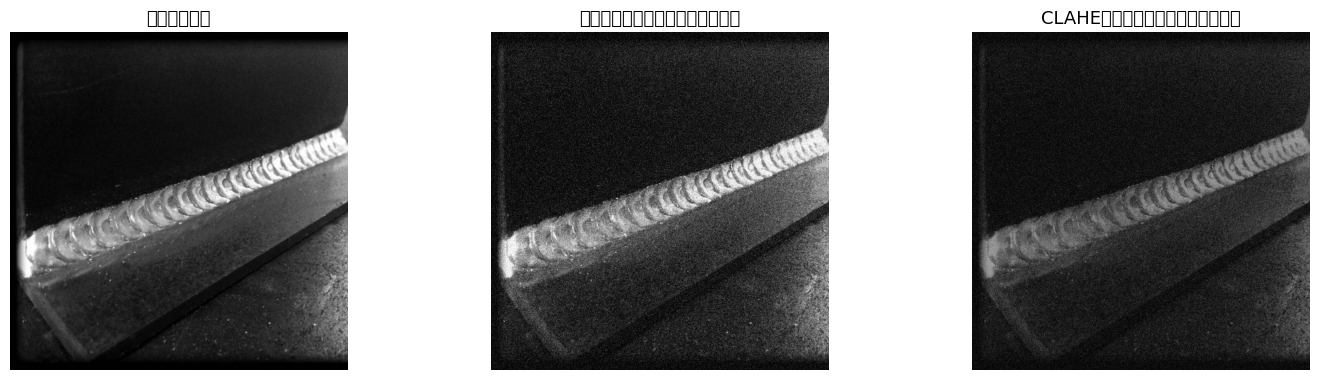


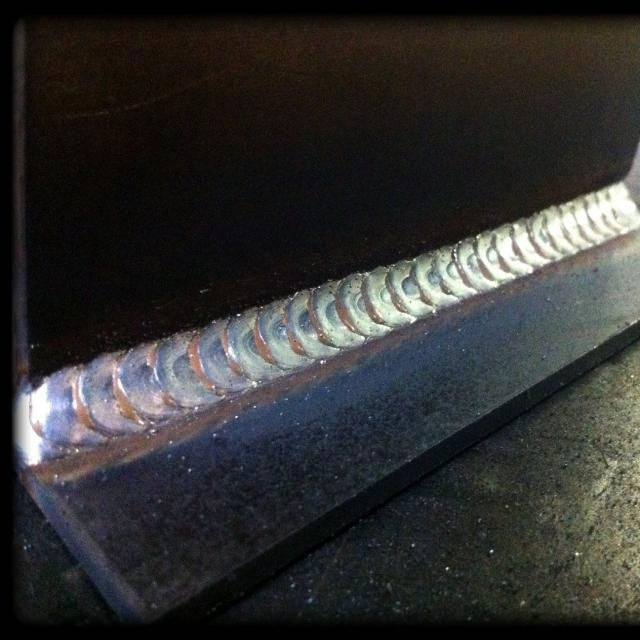
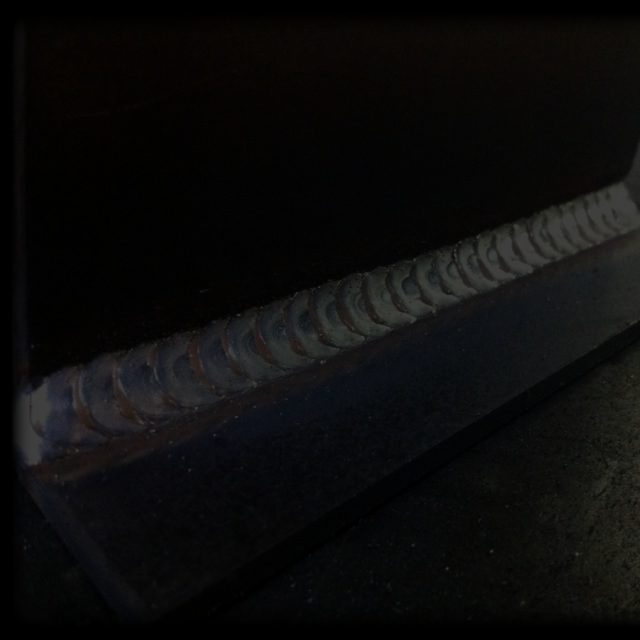
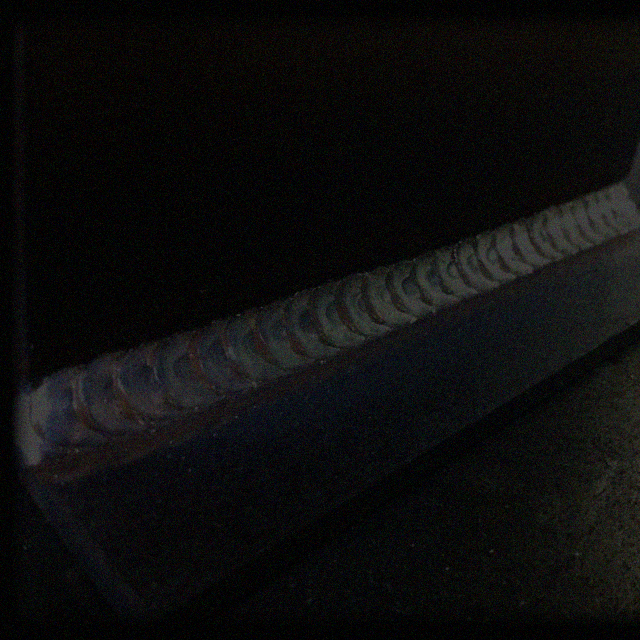
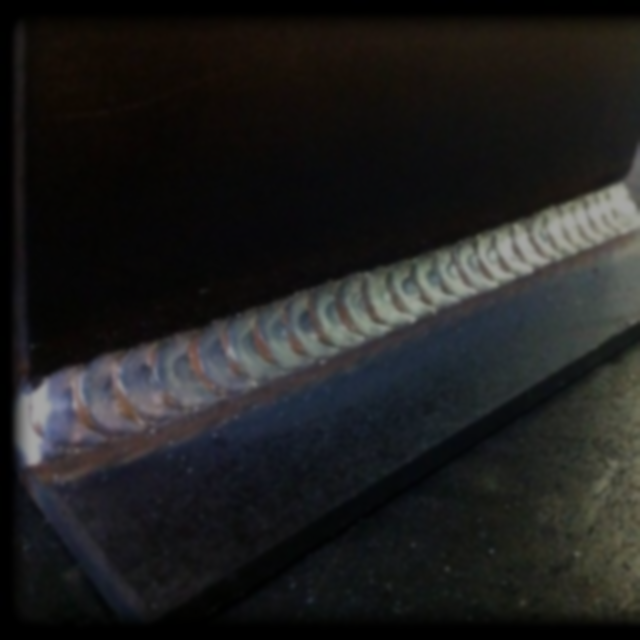
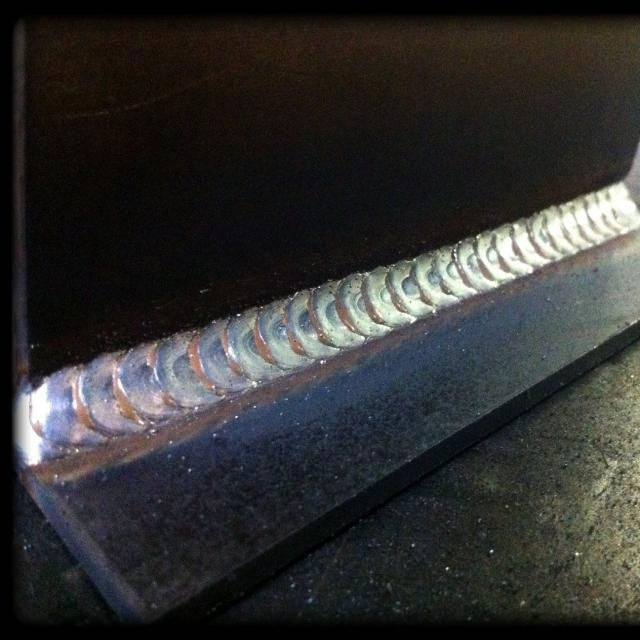

In [3]:
brightened = np.clip(dark_noisy.astype(np.float32) * 4, 0, 255).astype(np.uint8)
clahe = cv2.createCLAHE(clipLimit=2, tileGridSize=(8, 8)).apply(lab.gray(dark_noisy))
lab.show_images([lab.gray(image), lab.gray(brightened), clahe],
                ["原图灰度参考", "派生低亮噪声再放大：噪声也放大", "CLAHE：增强对比，不恢复真实细节"], cols=3)
display(HTML(lab.parameter_gallery([image, dark, dark_noisy, blurred],
    ["真实原图", "派生低亮", "派生低亮带噪声", "派生模糊"], "lighting")))

## 2. 算一格焊纹能占多少像素

物方采样约等于视野宽度 / 水平像素数。若一格最小可见纹理宽度为 0.15 mm，先用 8 像素做工程试验起点，这不是通用验收标准。镜头解析力、失焦、景深、压缩和运动都会使有效细节少于理论像素。

焦距主要改变视野和工作距离关系；远心镜头主要减少物体高度变化引起的倍率/透视变化，适合尺寸测量。远心镜头不会凭空增加像素或照亮焊纹。当前先实现“是否焊过”，应优先确认局部像素和打光，再决定是否需要远心。

In [4]:
sensor_width_px = 1920
feature_mm = 0.15
for fov_mm in [60, 120, 240]:
    feature_px = feature_mm * sensor_width_px / fov_mm
    print(f"视野 {fov_mm:3d} mm → 0.15 mm 特征约 {feature_px:.1f} px")
min_feature_px = 8  # 仅示例设计起点，必须用真实焊格复核
print("此假设下最大视野宽度 mm：", feature_mm * sensor_width_px / min_feature_px)

视野  60 mm → 0.15 mm 特征约 4.8 px
视野 120 mm → 0.15 mm 特征约 2.4 px
视野 240 mm → 0.15 mm 特征约 1.2 px
此假设下最大视野宽度 mm： 36.0


## 3. 现场四步试光记录

固定相机和工件距离，使用完整原图，不拍屏幕；分别记录环境光、漫射补光、左侧低角度、右侧低角度四种真实画面。尽量保持曝光、增益和白平衡一致；运动时缩短曝光，避免靠长曝光提亮。灯的频闪也要通过连续帧观察。

先用可见光比较清晰度与反光；只有真实对比表明特征分离改善，才决定红光、蓝光或近红外。RGB 通道拆分不是光谱实验，软件不能由一张普通照片证明换波长有效。保存请求值和实际回读，设备不支持曝光/对焦回读时填未知。

In [5]:
capture_recipe = {"camera_name": "OsmoAction4", "width": 1920, "height": 1080,
    "fps": 30, "max_detection_hz": 5,
    "lighting": {"scene": "night_fill_light", "lamp_on": True, "auto_exposure": True,
                 "exposure": None, "autofocus": True},
    "actual_exposure": None, "actual_autofocus": None,
    "note": "教学配置示例，不是相机已执行或已回读的证据"}
display(capture_recipe)
assert capture_recipe["actual_exposure"] is None

{'camera_name': 'OsmoAction4',
 'width': 1920,
 'height': 1080,
 'fps': 30,
 'max_detection_hz': 5,
 'lighting': {'scene': 'night_fill_light',
  'lamp_on': True,
  'auto_exposure': True,
  'exposure': None,
  'autofocus': True},
 'actual_exposure': None,
 'actual_autofocus': None,
 'note': '教学配置示例，不是相机已执行或已回读的证据'}

## 来源与练习边界

公开焊缝：sukmaadhiwijaya / rikkarth，固定提交 `8b80d1afe88c0b946500a498cbdb9d7a1eda5533`，数据卡声明 CC0-1.0；工业表面：Kolektor Group / ViCoS，CC BY-NC-SA 4.0；分散零件：Tung1213，CC BY-SA 3.0；重叠零件：Technologyfelix，CC BY-SA 4.0。相关照片和派生图保留原许可及署名。

完整来源、原许可页、下载路径及 SHA256 见 [DATA_SOURCES.md](../DATA_SOURCES.md) 和 [source_manifest.json](../sources/source_manifest.json)。本课是非商业教学。灰度、二值、叠框及扰动均为原照片的派生图，七格合成图另有醒目标记。它们不等于新增独立验收数据，也不证明电池焊接准确率或机械强度。